<a href="https://colab.research.google.com/github/kevinfoss74/superstore-sales-optimization/blob/main/super_store.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/train.csv')

**Transformación y Preparación de Datos**

In [ ]:
df.rename(columns={
    'Row ID': 'row_id',
    'Order ID' : 'order_id',
    'Order Date' : 'order_date',
    'Ship Date' : 'ship_date',
    'Ship Mode' : 'ship_mode',
    'Customer ID' : 'customer_id',
    'Customer Name' : 'customer_name',
    'Postal Code' : 'postal_code',
    'Product ID' : 'product_id',
    'Product Name' : 'product_name'
}, inplace=True )

In [ ]:
df.columns

Index(['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode',
       'customer_id', 'customer_name', 'Segment', 'Country', 'City', 'State',
       'postal_code', 'Region', 'product_id', 'Category', 'Sub-Category',
       'product_name', 'Sales'],
      dtype='object')

In [ ]:
df['postal_code'] = df['postal_code'].fillna(0)

In [ ]:
df.isnull().sum()

,0
row_id,0
order_id,0
order_date,0
ship_date,0
ship_mode,0
customer_id,0
customer_name,0
Segment,0
Country,0
City,0


In [ ]:
df.drop(['row_id'], axis=1, inplace=True)

In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)
df['ship_date'] = pd.to_datetime(df['ship_date'], dayfirst=True)
df['postal_code'] = pd.to_numeric(df['postal_code']).astype(int)

In [ ]:
df.dtypes

,0
order_id,object
order_date,datetime64[ns]
ship_date,datetime64[ns]
ship_mode,object
customer_id,object
customer_name,object
Segment,object
Country,object
City,object
State,object


In [ ]:
df.head()

,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,Segment,Country,City,State,postal_code,Region,product_id,Category,Sub-Category,product_name,Sales
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


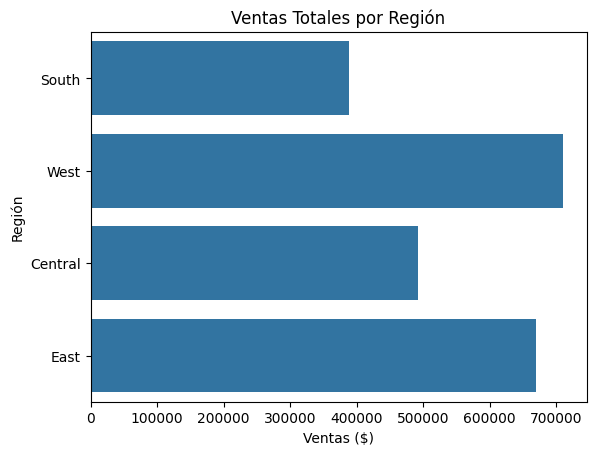

In [ ]:
import seaborn as sns

sns.barplot(data=df, x='Sales', y='Region', estimator=sum, errorbar=None)


plt.xlabel('Ventas ($)')
plt.ylabel('Región')
plt.title('Ventas Totales por Región')

plt.show()

La region del Oeste, es la principal consumidora

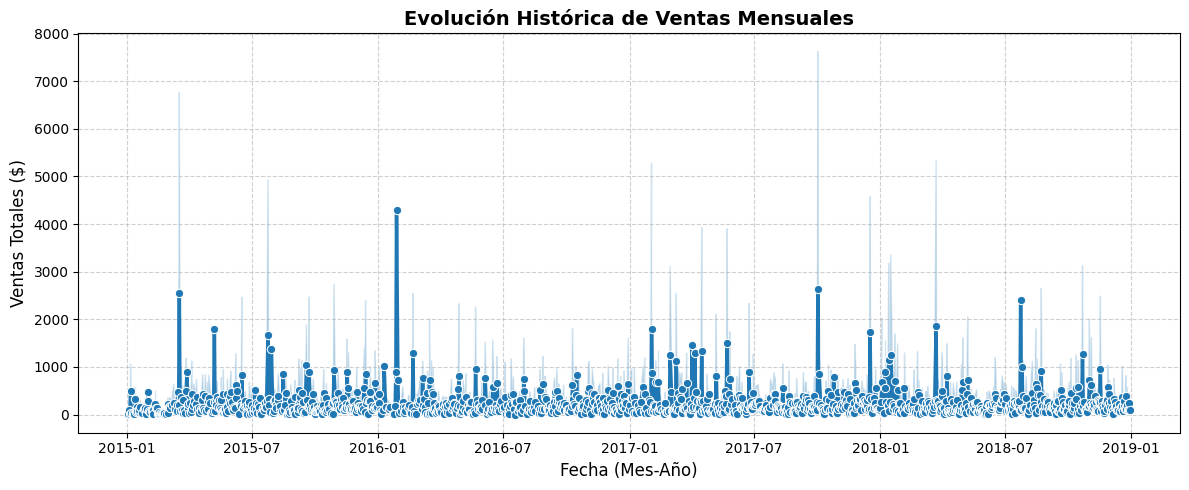

In [ ]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x='order_date', y='Sales', marker='o', color='#1f77b4', linewidth=2.5)

plt.title('Evolución Histórica de Ventas Mensuales', fontsize=14, fontweight='bold')
plt.xlabel('Fecha (Mes-Año)', fontsize=12)
plt.ylabel('Ventas Totales ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

De los ultimos años, los meses de enero y julio fueron los que mas ventas se registraron.

/tmp/ipykernel_2226/1882152092.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


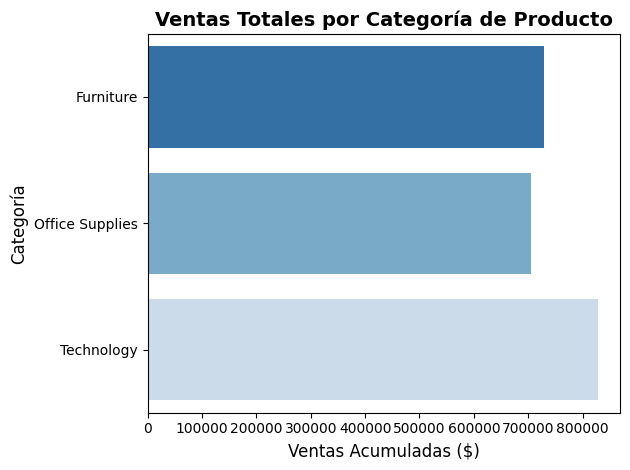

In [ ]:
sns.barplot(
    data=df,
    y='Category',
    x='Sales',
    estimator=sum,
    errorbar=None,
    palette='Blues_r'
)

plt.title('Ventas Totales por Categoría de Producto', fontsize=14, fontweight='bold')
plt.xlabel('Ventas Acumuladas ($)', fontsize=12)
plt.ylabel('Categoría', fontsize=12)

plt.tight_layout()
plt.show()

Tecnologia, muebles y suministros de oficina, son las categorias que mas se venden.

**Ingeniería de Características (Feature Engineering)**

In [ ]:
df.columns

Index(['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id',
       'customer_name', 'Segment', 'Country', 'City', 'State', 'postal_code',
       'Region', 'product_id', 'Category', 'Sub-Category', 'product_name',
       'Sales'],
      dtype='object')

In [ ]:
# dias transcurrido entre el pedido y el envio
df['days_to_ship'] = (df['ship_date'] - df['order_date']).dt.days
df['order_year'] = df['order_date'].dt.year # ventas por año
df['order_month'] = df['order_date'].dt.month #numero del mes
df['order_day'] = df['order_date'].dt.day #dia del mes 1-31
df['order_dayofweek'] = df['order_date'].dt.dayofweek  # 0 = Lunes, 6 = Domingo
df['is_weekend'] = df['order_dayofweek'].apply(lambda x: 1 if x >= 5 else 0)

Analisis de Negocio

In [ ]:
# ¿Qué año tuvo el mayor volumen de ventas?
ventas_ano = df.groupby('order_year')['Sales'].sum().sort_values(ascending=False)
print("Ventas totales por año:")
print(ventas_ano)
print(f"\n--> El año con mayor volumen de ventas fue {ventas_ano.index[0]} con ${ventas_ano.iloc[0]:,.2f}\n")

Ventas totales por año:
order_year
2018    722052.0192
2017    600192.5500
2015    479856.2081
2016    459436.0054
Name: Sales, dtype: float64

--> El año con mayor volumen de ventas fue 2018 con $722,052.02



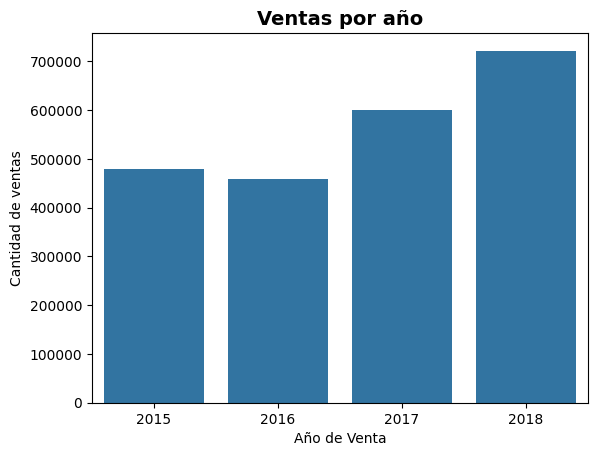

In [ ]:
sns.barplot(x=ventas_ano.index, y=ventas_ano.values)

plt.title('Ventas por año', fontsize=14, fontweight='bold')
plt.xlabel('Año de Venta')
plt.ylabel('Cantidad de ventas')

plt.show()

In [ ]:
# ¿Se vende más los fines de semana o los días laborales?
ventas_tipo_dia = df.groupby('is_weekend')['Sales'].agg(['sum', 'mean', 'count'])
ventas_tipo_dia.columns = ['Ventas_Totales', 'Promedio_por_Orden', 'Cantidad_Ordenes']
print("Comparativa Fin de Semana vs Día Laboral:")
print(ventas_tipo_dia)
print()

Comparativa Fin de Semana vs Día Laboral:
            Ventas_Totales  Promedio_por_Orden  Cantidad_Ordenes
is_weekend                                                      
0             1.462767e+06          231.487028              6319
1             7.987703e+05          229.465744              3481



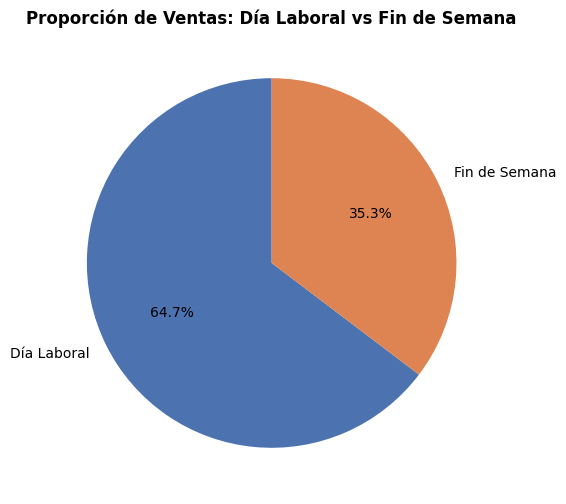

In [ ]:
etiquetas = ['Día Laboral', 'Fin de Semana']

plt.figure(figsize=(6, 6))
plt.pie(
    ventas_tipo_dia['Ventas_Totales'],
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#4C72B0', '#DD8452']
)

plt.title('Proporción de Ventas: Día Laboral vs Fin de Semana', fontsize=12, fontweight='bold')
plt.show()

In [ ]:
# Top 5 estados con mejores y peores ventas
ventas_estado = df.groupby('State')['Sales'].sum().sort_values(ascending=False)
print("Top 5 Estados con MEJORES ventas:")
print(ventas_estado.head(5))
print("\nTop 5 Estados con PEORES ventas:")
print(ventas_estado.tail(5))
print()

Top 5 Estados con MEJORES ventas:
State
California      446306.4635
New York        306361.1470
Texas           168572.5322
Washington      135206.8500
Pennsylvania    116276.6500
Name: Sales, dtype: float64

Top 5 Estados con PEORES ventas:
State
Wyoming          1603.136
South Dakota     1315.560
Maine            1270.530
West Virginia    1209.824
North Dakota      919.910
Name: Sales, dtype: float64



/tmp/ipykernel_2226/284684553.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x= ventas_estado.head(5).index, y = ventas_estado.head(5).values,palette='Blues_r' )


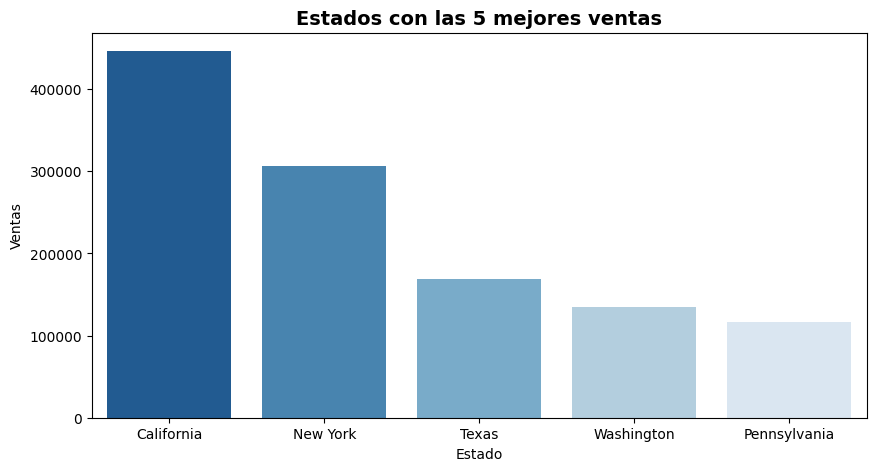

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x= ventas_estado.head(5).index, y = ventas_estado.head(5).values,palette='Blues_r' )

plt.title('Estados con las 5 mejores ventas', fontsize=14, fontweight='bold')
plt.xlabel('Estado')
plt.ylabel('Ventas')

plt.show()



In [ ]:
# Subcategorías de productos más vendidas frente a las menos vendidas
ventas_subcat = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)
print("Top 3 Subcategorías MÁS vendidas:")
print(ventas_subcat.head(3))
print("\nTop 3 Subcategorías MENOS vendidas:")
print(ventas_subcat.tail(3))
print("\n" + "="*50 + "\n")

Top 3 Subcategorías MÁS vendidas:
Sub-Category
Phones     327782.448
Chairs     322822.731
Storage    219343.392
Name: Sales, dtype: float64

Top 3 Subcategorías MENOS vendidas:
Sub-Category
Envelopes    16128.046
Labels       12347.726
Fasteners     3001.960
Name: Sales, dtype: float64




In [ ]:
# Promedio de días de despacho por modo de envío
logistica_envio = df.groupby('ship_mode')['days_to_ship'].agg(['mean', 'min', 'max']).round(2)
logistica_envio.columns = ['Promedio_Dias', 'Minimo_Dias', 'Maximo_Dias']
print("Tiempos de despacho por modo de envío:")
print(logistica_envio)

Tiempos de despacho por modo de envío:
                Promedio_Dias  Minimo_Dias  Maximo_Dias
ship_mode                                              
First Class              2.18            1            4
Same Day                 0.04            0            1
Second Class             3.25            1            5
Standard Class           5.01            3            7


**Modelado de Machine Learning**

In [ ]:
df.columns

Index(['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id',
       'customer_name', 'Segment', 'Country', 'City', 'State', 'postal_code',
       'Region', 'product_id', 'Category', 'Sub-Category', 'product_name',
       'Sales', 'days_to_ship', 'order_year', 'order_month', 'order_day',
       'order_dayofweek', 'is_weekend'],
      dtype='object')

In [ ]:
import numpy as np


In [ ]:
y = df.Sales

In [ ]:
drop_columns = [
    'order_id', 'customer_id', 'customer_name',
    'product_id', 'product_name', 'postal_code', 'Country',
    'order_date', 'ship_date', 'Sales'
]

In [ ]:
X = df.drop(drop_columns, axis=1)

In [ ]:
X_encoded = pd.get_dummies(X, drop_first=True)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42)
tree.fit(X_train , y_train)

DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42)

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

In [ ]:
print("--- RESULTADOS DEL MODELO CORREGIDO ---")
print("R² en Entrenamiento:", round(r2_score(y_train, y_train_pred), 4))
print("R² en Evaluación (Test):", round(r2_score(y_test, y_test_pred), 4))
print(f"Error Promedio Absoluto (MAE): ${mean_absolute_error(y_test, y_test_pred):.2f}")

--- RESULTADOS DEL MODELO CORREGIDO ---
R² en Entrenamiento: 0.4012
R² en Evaluación (Test): 0.0275
Error Promedio Absoluto (MAE): $259.16


In [ ]:
import numpy as np

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
mediana_sales = df['Sales'].median()
y_class = np.where(df['Sales'] > mediana_sales, 1, 0)

In [ ]:
drop_cols = ['order_id', 'customer_id', 'customer_name', 'product_id',
             'product_name', 'postal_code', 'City', 'Country',
             'order_date', 'ship_date', 'Sales']

In [ ]:
X = df.drop(columns=drop_cols, axis=1)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_class, test_size=0.2, random_state=42, stratify=y_class)

In [ ]:
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
print("Accuracy Train:", round(accuracy_score(y_train, clf.predict(X_train)), 4))
print("Accuracy Test:", round(accuracy_score(y_test, clf.predict(X_test)), 4))

Accuracy Train: 0.7764
Accuracy Test: 0.7653


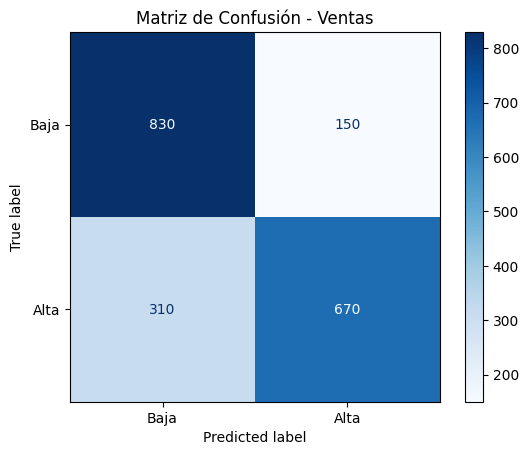

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generar la matriz de confusión sobre el conjunto de evaluación
cm = confusion_matrix(y_test, clf.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Baja', 'Alta'])

disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Ventas')
plt.show()


Al redefinir el problema hacia un enfoque de clasificación binaria (separando transacciones en 'Venta Alta' y 'Venta Baja' mediante la mediana), el modelo DecisionTreeClassifier alcanzó un 76.53% de precisión (Accuracy) en el conjunto de evaluación. La consistencia entre el rendimiento de Train (77.59%) y Test (76.53%) valida la estabilidad del modelo y evita el sobreajuste.  


COMPETENCIA DE MODELOS


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score


modelos = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42)
}

print("--- 1. COMPETENCIA DE MODELOS ---")
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    acc = accuracy_score(y_test, modelo.predict(X_test))
    print(f"Modelo: {nombre:<20} | Accuracy en Test: {acc:.4f}")



--- 1. COMPETENCIA DE MODELOS ---
Modelo: Decision Tree        | Accuracy en Test: 0.7653
Modelo: Random Forest        | Accuracy en Test: 0.7230
Modelo: Logistic Regression  | Accuracy en Test: 0.7633


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


 OPTIMIZACIÓN DE HIPERPARÁMETROS

In [ ]:
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
mejor_modelo = grid_search.best_estimator_

print("\n--- 2. OPTIMIZACIÓN DE HIPERPARÁMETROS (GridSearchCV) ---")
print("Mejores Parámetros Encontrados:", grid_search.best_params_)
acc_opt = accuracy_score(y_test, mejor_modelo.predict(X_test))
print(f"Accuracy del Mejor Modelo Optimizado: {acc_opt:.4f}")




--- 2. OPTIMIZACIÓN DE HIPERPARÁMETROS (GridSearchCV) ---
Mejores Parámetros Encontrados: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Accuracy del Mejor Modelo Optimizado: 0.7653


ESTIMACIÓN DE LA INCERTIDUMBRE (Cross-Validation)

In [ ]:
cv_scores = cross_val_score(mejor_modelo, X_encoded, y_class, cv=10, scoring='accuracy')

print("\n--- 3. ESTIMACIÓN DE LA INCERTIDUMBRE (Cross-Validation) ---")
print(f"Accuracy Promedio: {np.mean(cv_scores):.4f}")
print(f"Desviación Estándar (Incertidumbre): ±{np.std(cv_scores):.4f}")
print(f"Rango de Confianza al 95%: [{np.mean(cv_scores) - 2*np.std(cv_scores):.4f} , {np.mean(cv_scores) + 2*np.std(cv_scores):.4f}]")


--- 3. ESTIMACIÓN DE LA INCERTIDUMBRE (Cross-Validation) ---
Accuracy Promedio: 0.7700
Desviación Estándar (Incertidumbre): ±0.0112
Rango de Confianza al 95%: [0.7476 , 0.7924]


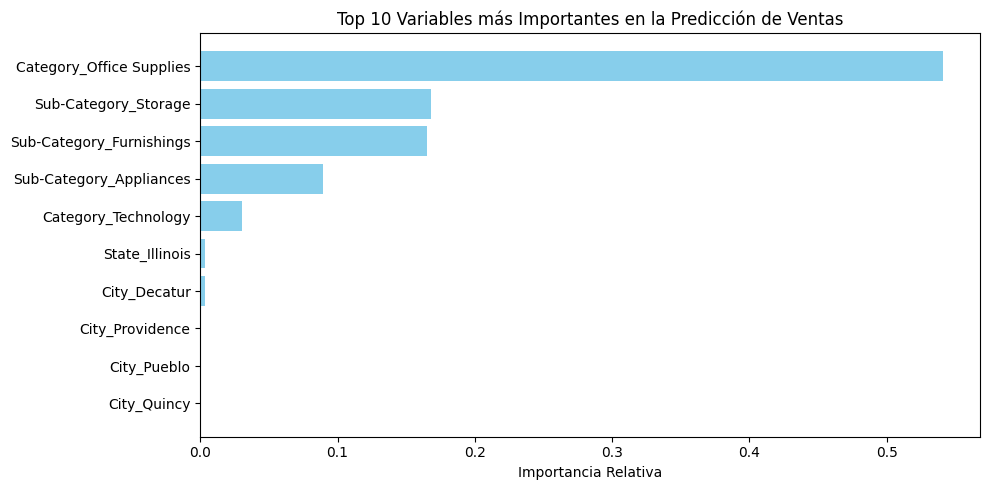

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Obtener la importancia de las variables del mejor modelo
importancias = mejor_modelo.feature_importances_
columnas = X_encoded.columns

# Crear DataFrame y ordenar las 10 más importantes
df_imp = pd.DataFrame({'Variable': columnas, 'Importancia': importancias})
df_imp = df_imp.sort_values(by='Importancia', ascending=False).head(10)

# Graficar
plt.figure(figsize=(10, 5))
plt.barh(df_imp['Variable'], df_imp['Importancia'], color='skyblue')
plt.gca().invert_yaxis()
plt.title('Top 10 Variables más Importantes en la Predicción de Ventas')
plt.xlabel('Importancia Relativa')
plt.tight_layout()
plt.show()

# Conclusiones del Proyecto Final
+ 1 Definición del Problema: Ante la alta varianza del monto continuo de ventas (R
2
 =0.0275 en regresión), se transformó la meta analítica a un problema de clasificación binaria tomando la mediana ($54.50).   

+ 2
Competencia de Algoritmos: Se evaluaron tres algoritmos (Decision Tree, Random Forest y Logistic Regression). El Árbol de Decisión demostró ser la mejor opción técnica por su equilibrio entre interpretabilidad y rendimiento (Accuracy: 76.53%).   

+ 3
Optimización de Hiperparámetros: A través de GridSearchCV, se determinó que la estructura óptima del árbol se alcanza con max_depth=5, evitando el sobreajuste (overfitting) al mantener métricas alineadas entre Entrenamiento (77.64%) y Evaluación (76.53%).   

+ 4
Incertidumbre: La validación cruzada de 10 pliegues (10-Fold CV) confirmó la estabilidad del modelo con una precisión esperada de 77.00%±1.12%.   

+ 5
Impacto de Negocio: Este clasificador permite filtrado y priorización en tiempo real de transacciones para optimizar la logística de despacho y segmentar estrategias comerciales según el volumen estimado de la orden.

In [ ]:
# 1. Generar predicciones sobre todo el dataset codificado (o el conjunto de evaluación)
df['Prediccion_Modelo'] = mejor_modelo.predict(X_encoded)  # Devuelve 0 o 1[cite: 3, 12]
df['Categoria_Predicha'] = df['Prediccion_Modelo'].map({0: 'Venta Baja', 1: 'Venta Alta'})

# 2. (Opcional) Guardar también un CSV de respaldo directo
df.to_csv('superstore_final_predicciones.csv', index=False)